# Employee Attrition Prediction — EDA and Modeling

This notebook walks through the full pipeline: **data → cleaning → EDA → preprocessing → model tuning and comparison → prediction**.
All heavy lifting lives in the reusable modules under `src/`; the notebook calls them and explains the results.

Run it from the `notebooks/` folder (or open it in Jupyter / VS Code) after generating the data:

```bash
python -m src.generate_data
```

In [1]:
import sys, tempfile, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))      # make the `src` package importable
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

from src import eda
from src.predict import AttritionPredictor, InputValidationError
from src.preprocessing import (build_preprocessor, clean_data, get_feature_names, load_data,
                               split_features_target, split_train_test)
from src.train_model import run_training
from src.utils import DATA_PATH

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Load the raw data
The generated file deliberately contains missing values, inconsistent text and a few impossible entries, like a real HR export.

In [2]:
raw = load_data(DATA_PATH)
print(raw.shape)
raw.head()

(1500, 11)


,EmployeeID,Age,Department,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,PerformanceRating,OverTime,DistanceFromHome,Attrition
0,1001,43.000,Marketing,"71,700.000",2,1.000,3.000,4,No,8.000,No
1,1002,29.000,Engineering,"85,900.000",6,5.000,5.000,4,No,3.000,No
2,1003,28.000,Finance,"59,900.000",5,3.000,2.000,4,No,6.000,Yes
3,1004,39.000,Marketing,"108,700.000",13,4.000,3.000,5,Yes,6.000,No
4,1005,43.000,Sales,"70,800.000",18,4.000,1.000,4,No,NaN,No


In [3]:
# Missing values per column (raw file)
raw.isna().sum().to_frame("missing").query("missing > 0")

,missing
Age,22
Department,30
MonthlyIncome,45
JobSatisfaction,45
WorkLifeBalance,30
DistanceFromHome,37


## 2. Clean the data
`clean_data` fixes text casing and turns impossible values (negative age, satisfaction of 9 ...) into missing values. It learns nothing from the data, so it is safe before the train/test split. Imputation happens later, *inside* the model pipeline.

In [4]:
df = clean_data(raw)
print("Unique departments :", sorted(df["Department"].dropna().unique()))
print("OverTime values    :", sorted(df["OverTime"].dropna().unique()))
print("Remaining missing  :", int(df.isna().sum().sum()), "cells (imputed inside the pipeline)")

12:16:12 | INFO    | Cleaning fixed/flagged: {'invalid_Age': 4, 'invalid_MonthlyIncome': 4, 'invalid_DistanceFromHome': 4, 'invalid_JobSatisfaction': 4}


Unique departments : ['Engineering', 'Finance', 'HR', 'Marketing', 'Sales']
OverTime values    : ['No', 'Yes']
Remaining missing  : 225 cells (imputed inside the pipeline)


## 3. Exploratory data analysis

In [5]:
overall = eda.overall_attrition_rate(df)
print(f"Overall attrition rate: {overall:.1%}  ->  imbalanced classes")
df["Attrition"].value_counts().to_frame("employees")

Overall attrition rate: 15.9%  ->  imbalanced classes


,employees
Attrition,
No,1261
Yes,239


In [6]:
results = eda.run_eda(df)          # saves all EDA plots to visuals/
for line in results["insights"]:
    print("•", line)

12:16:12 | INFO    | Saved plot -> /home/claude/Employee-Attrition-Prediction/visuals/attrition_by_department.png


12:16:13 | INFO    | Saved plot -> /home/claude/Employee-Attrition-Prediction/visuals/attrition_by_overtime.png


12:16:13 | INFO    | Saved plot -> /home/claude/Employee-Attrition-Prediction/visuals/attrition_by_job_satisfaction.png


12:16:13 | INFO    | Saved plot -> /home/claude/Employee-Attrition-Prediction/visuals/income_boxplot.png


12:16:13 | INFO    | Saved plot -> /home/claude/Employee-Attrition-Prediction/visuals/correlation_heatmap.png


...

12:16:14 | INFO    | INSIGHT: Attrition falls as job satisfaction rises: 30.8% at score 1 versus 9.5% at score 5.


12:16:14 | INFO    | INSIGHT: Median monthly income is ₹59,100 for leavers versus ₹77,000 for stayers (-23%).


12:16:14 | INFO    | INSIGHT: Employees with up to 1 year at the company leave at 34.8%, compared with 11.7% for those with 5+ years.


12:16:14 | INFO    | INSIGHT: Top factors by combined correlation / mutual-information rank: MonthlyIncome, Age, Department_Sales, YearsAtCompany, JobSatisfaction.


• Overall attrition rate is 15.9% (239 of 1500 employees), so the classes are imbalanced.
• Sales has the highest attrition (24.9%); Engineering has the lowest (10.5%).
• Employees working overtime leave at 23.0% versus 12.9% without overtime (1.8x higher).
• Attrition falls as job satisfaction rises: 30.8% at score 1 versus 9.5% at score 5.
• Median monthly income is ₹59,100 for leavers versus ₹77,000 for stayers (-23%).
• Employees with up to 1 year at the company leave at 34.8%, compared with 11.7% for those with 5+ years.
• Top factors by combined correlation / mutual-information rank: MonthlyIncome, Age, Department_Sales, YearsAtCompany, JobSatisfaction.


In [7]:
eda.attrition_rate_by(df, "Department")

,Department,employees,leavers,attrition_rate
0,Sales,437,109,0.249
1,Marketing,186,28,0.151
2,HR,119,16,0.134
3,Finance,279,30,0.108
4,Engineering,449,47,0.105


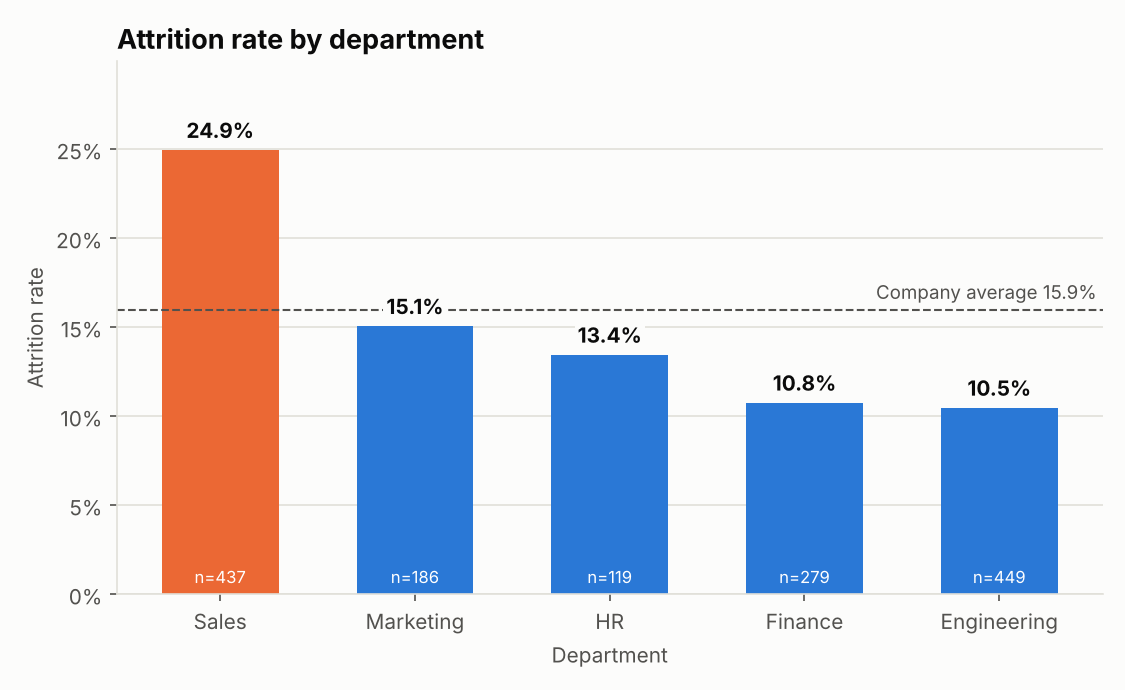

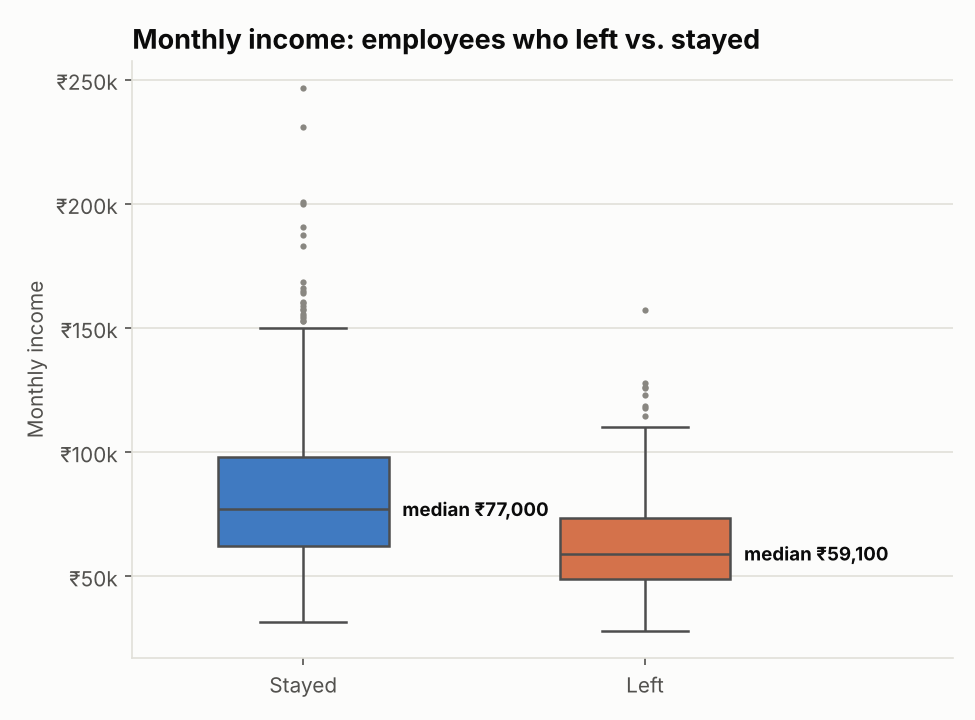

In [8]:
display(Image(filename="../visuals/attrition_by_department.png"))
display(Image(filename="../visuals/income_boxplot.png"))

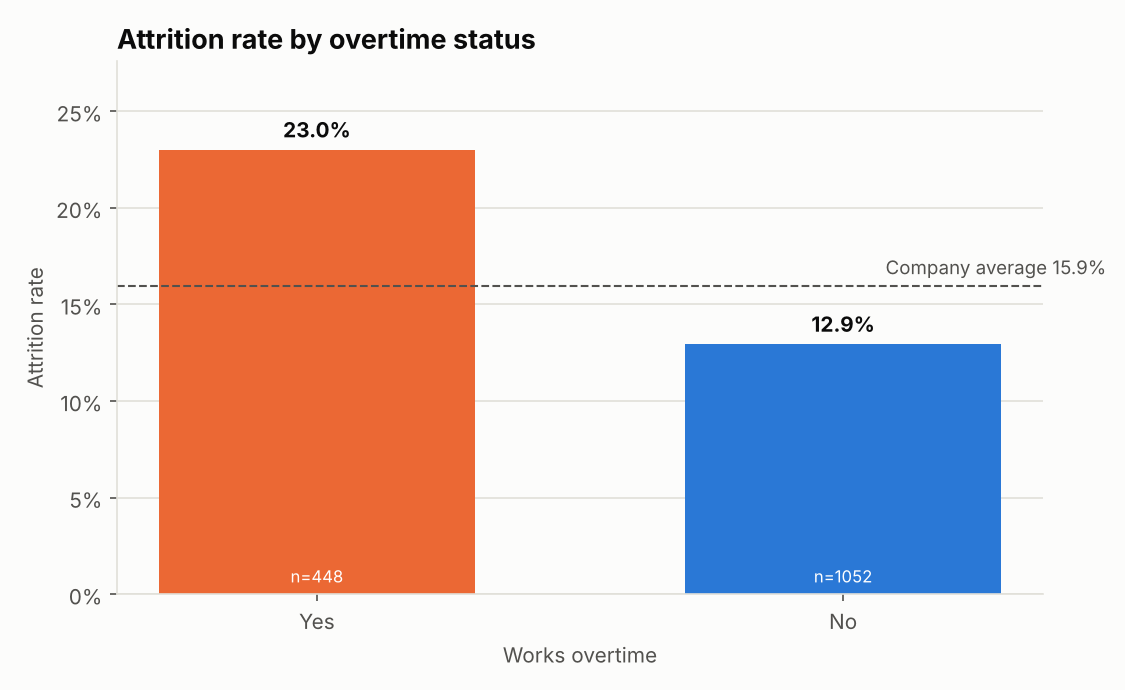

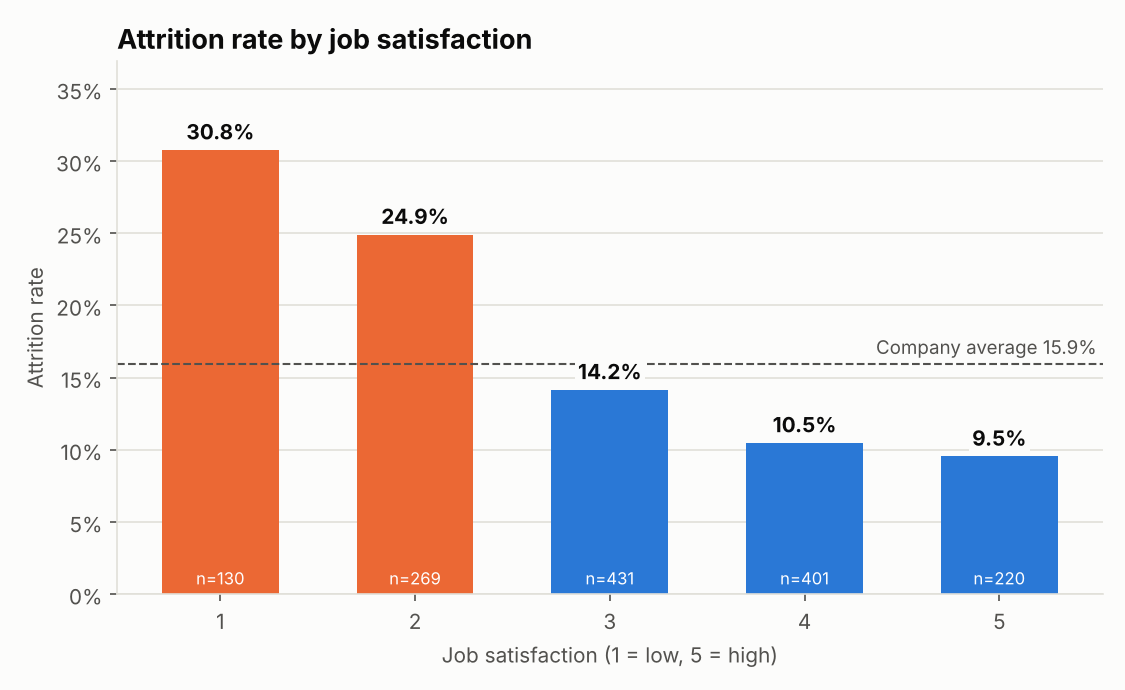

In [9]:
display(Image(filename="../visuals/attrition_by_overtime.png"))
display(Image(filename="../visuals/attrition_by_job_satisfaction.png"))

### Correlations and top factors

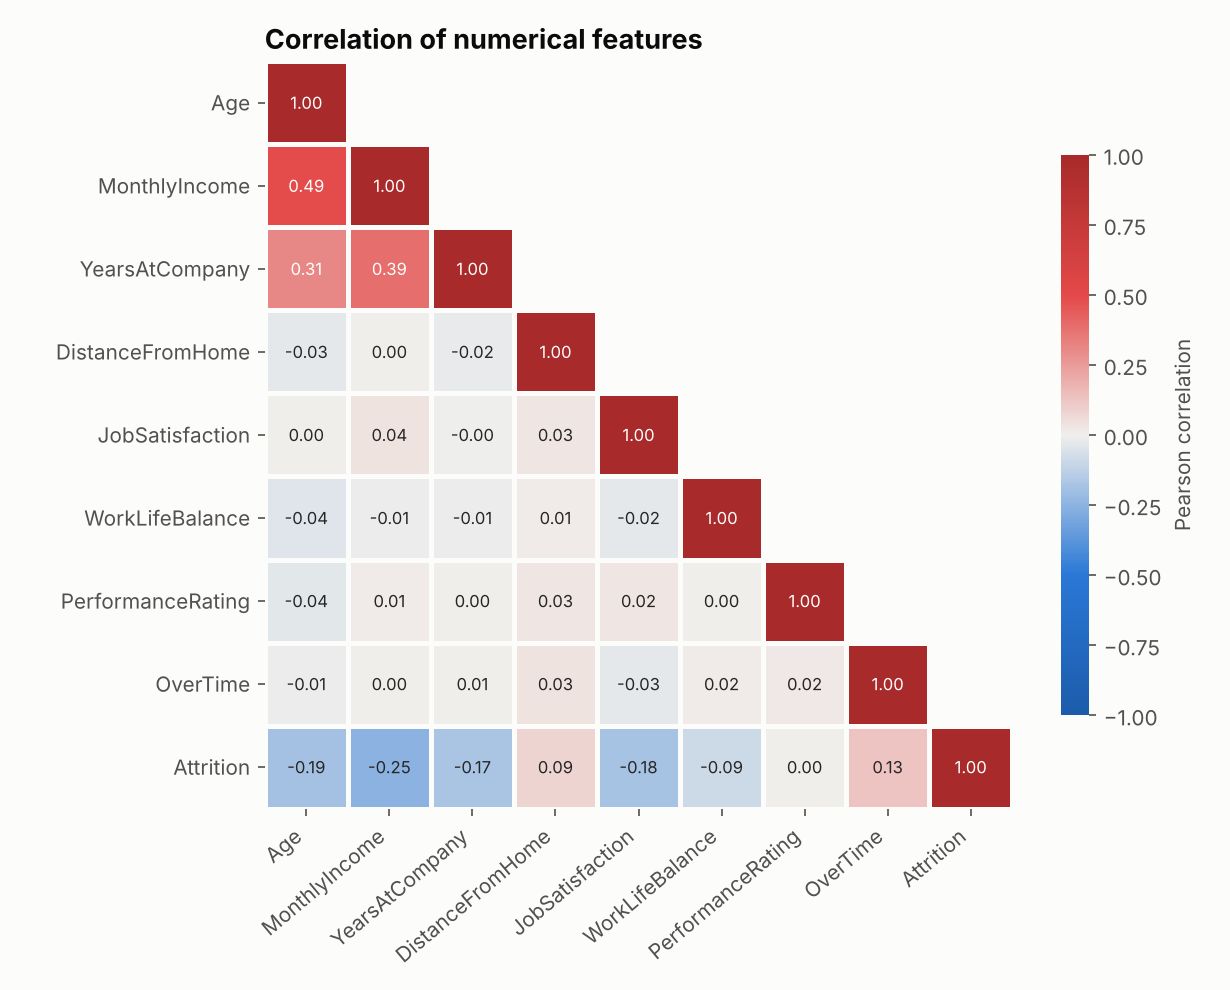

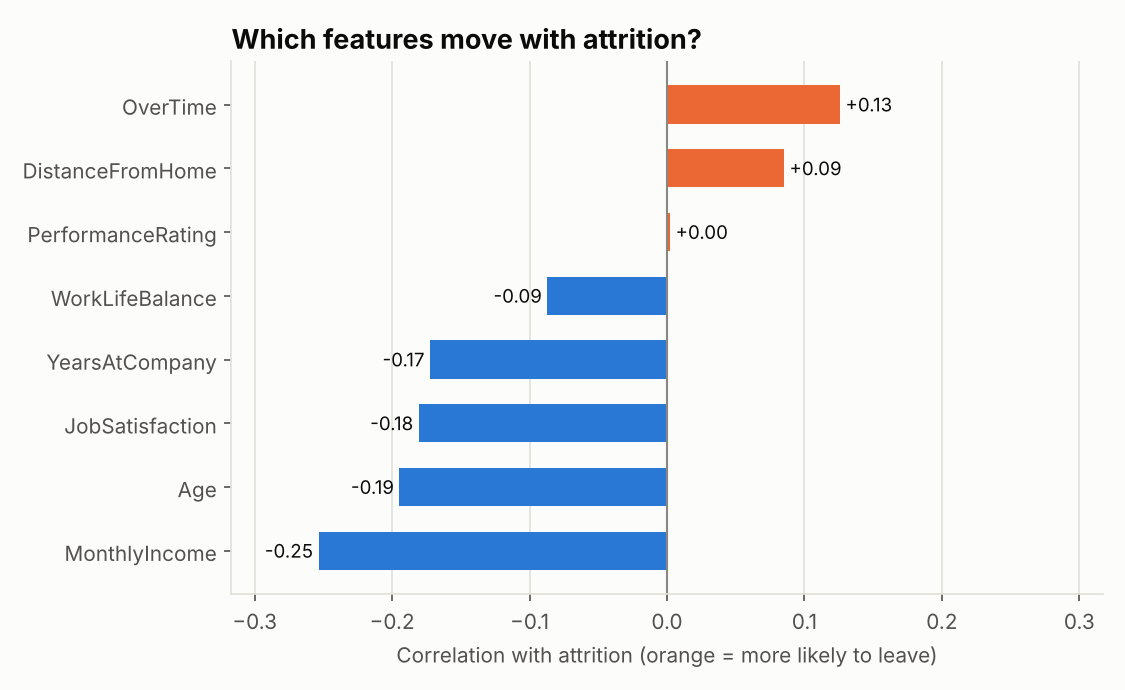

In [10]:
display(Image(filename="../visuals/correlation_heatmap.png"))
display(Image(filename="../visuals/correlation_with_attrition.png"))

In [11]:
# Combined ranking: |correlation| and mutual information with attrition
results["ranking"][["feature", "correlation", "mutual_info", "avg_rank"]].head(8)

,feature,correlation,mutual_info,avg_rank
0,MonthlyIncome,-0.276,0.047,1.000
1,Age,-0.193,0.021,2.500
2,Department_Sales,0.158,0.026,3.500
3,YearsAtCompany,-0.172,0.013,4.500
4,JobSatisfaction,-0.178,0.013,4.500
5,WorkLifeBalance,-0.086,0.016,5.500
6,Department_Finance,-0.068,0.009,8.500
7,OverTime,0.126,0.000,8.750


## 4. Preprocessing and leakage control
The `ColumnTransformer` imputes (median / most frequent), log-transforms income, scales numeric features and encodes categoricals.
It is **fitted on the training split only**; the test split is merely transformed.

In [12]:
X, y = split_features_target(df)
X_train, X_test, y_train, y_test = split_train_test(X, y)
print(f"train {X_train.shape}, test {X_test.shape}")
print(f"attrition rate  train {y_train.mean():.1%}  |  test {y_test.mean():.1%}  (stratified split)")

preprocessor = build_preprocessor().fit(X_train)
print("Model input features:", get_feature_names(preprocessor))

train (1200, 9), test (300, 9)
attrition rate  train 15.9%  |  test 16.0%  (stratified split)
Model input features: ['Age', 'YearsAtCompany', 'DistanceFromHome', 'JobSatisfaction', 'WorkLifeBalance', 'PerformanceRating', 'MonthlyIncome', 'Department_Sales', 'Department_Engineering', 'Department_HR', 'Department_Marketing', 'Department_Finance', 'OverTime']


## 5. Train, tune and compare models
`run_training` tunes Logistic Regression (grid search), Random Forest and XGBoost (randomised search) with 5-fold stratified CV on the training data,
handles imbalance with **class weighting**, then scores each model once on the held-out test set.
Here it writes to a temporary folder so the notebook never overwrites the project's saved model (results are identical because all seeds are fixed).
It takes about a minute.

In [13]:
workdir = Path(tempfile.mkdtemp())
summary = run_training(DATA_PATH, imbalance="class_weight", models_dir=workdir / "models",
                       visuals_dir=workdir / "visuals")
comparison = pd.DataFrame(summary["comparison"]).set_index("model")
comparison

12:16:14 | INFO    | Cleaning fixed/flagged: {'invalid_Age': 4, 'invalid_MonthlyIncome': 4, 'invalid_DistanceFromHome': 4, 'invalid_JobSatisfaction': 4}


12:16:14 | INFO    | Train: 1200 rows (15.9% attrition) | Test: 300 rows (16.0% attrition)


12:16:14 | INFO    | Tuning Logistic Regression (grid search)...


12:16:16 | INFO    |   Logistic Regression: CV AUC 0.786 | test AUC 0.777, F1 0.446, recall 0.688 (2.6s)


12:16:16 | INFO    | Tuning Random Forest (random search)...


...

12:17:17 | INFO    | Saved plot -> /tmp/tmpo5bno8hh/visuals/roc_curves.png


12:17:17 | INFO    | Saved plot -> /tmp/tmpo5bno8hh/visuals/confusion_matrix.png


12:17:18 | INFO    | Saved plot -> /tmp/tmpo5bno8hh/visuals/shap_summary.png


12:17:18 | INFO    | Saved best model (Logistic Regression) -> /tmp/tmpo5bno8hh/models/best_model.pkl


,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,tuning_seconds
model,,,,,,,
Logistic Regression,0.786,0.727,0.330,0.688,0.446,0.777,2.600
Random Forest,0.773,0.770,0.356,0.542,0.430,0.766,51.000
XGBoost,0.766,0.737,0.337,0.667,0.448,0.757,5.400


In [14]:
print("Best model:", summary["best_model"])
print()
print(summary["justification"])

Best model: Logistic Regression

Logistic Regression was selected because it achieved the highest cross-validated ROC-AUC (0.786, ahead of Random Forest by +0.013). ROC-AUC measures how well a model ranks leavers above stayers regardless of the decision threshold, which suits an imbalanced problem where plain accuracy is misleading. On the untouched test set it reached ROC-AUC 0.777, recall 0.688, precision 0.330 and F1 0.446. Selection used cross-validation on the training data only, so the test metrics are an unbiased estimate of real-world performance.


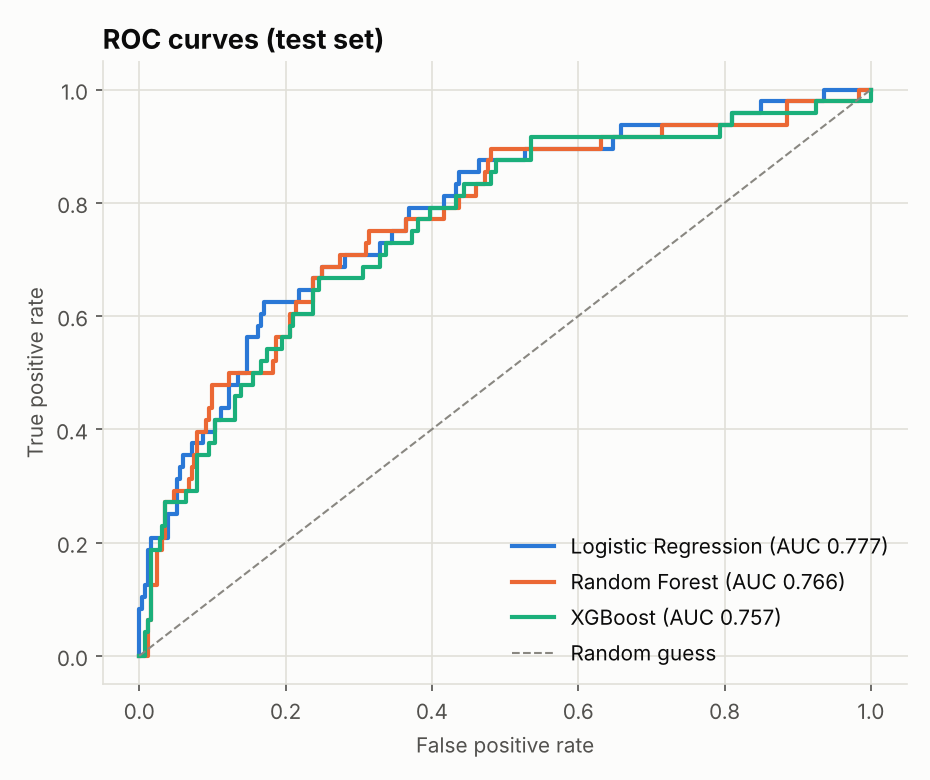

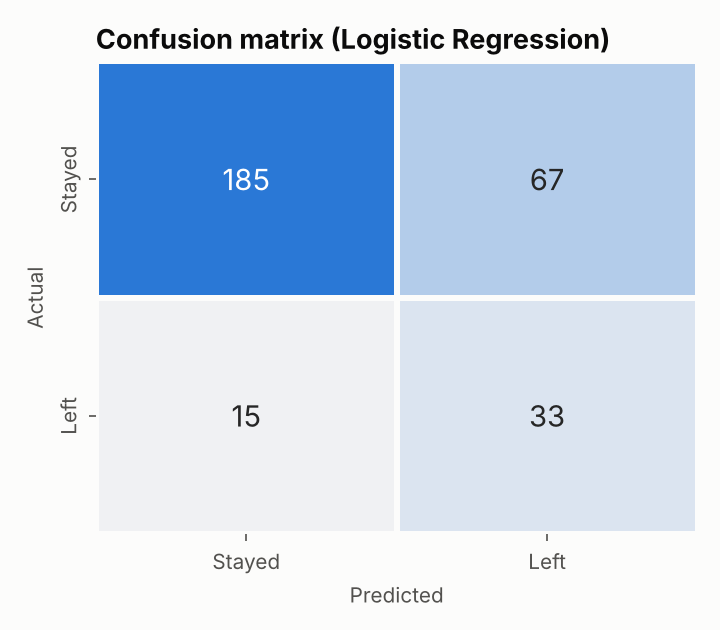

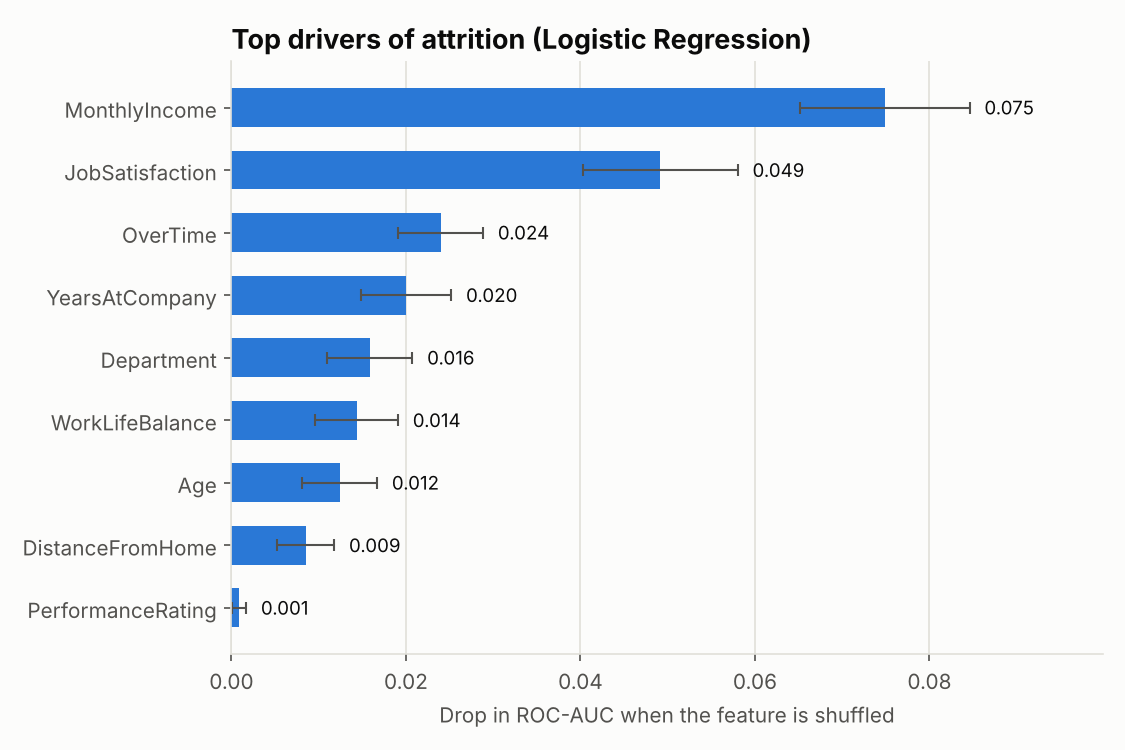

In [15]:
display(Image(filename=workdir / "visuals" / "roc_curves.png"))
display(Image(filename=workdir / "visuals" / "confusion_matrix.png"))
display(Image(filename=workdir / "visuals" / "feature_importance.png"))

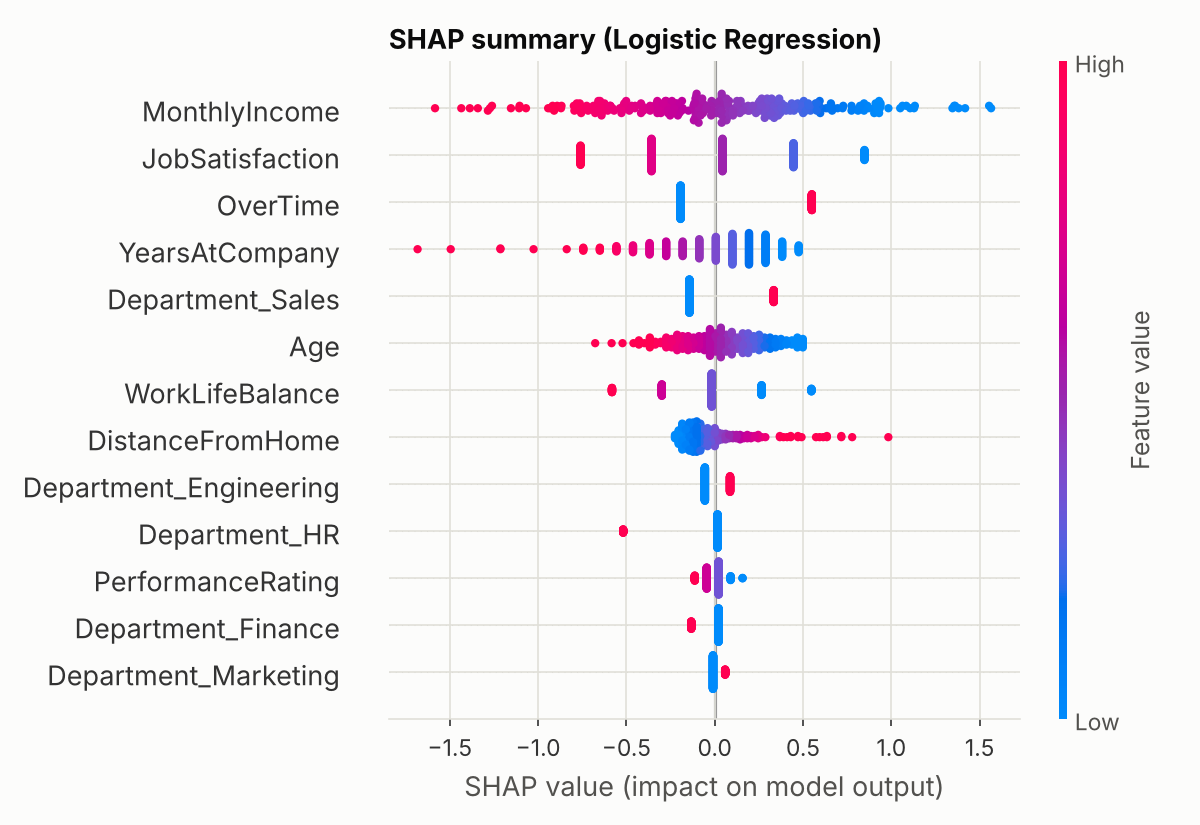

In [16]:
display(Image(filename=workdir / "visuals" / "shap_summary.png"))

## 6. Make predictions with the saved model

In [17]:
predictor = AttritionPredictor(workdir / "models" / "best_model.pkl")

high_risk = {"Age": 24, "Department": "Sales", "MonthlyIncome": 22000, "YearsAtCompany": 0,
             "JobSatisfaction": 1, "WorkLifeBalance": 1, "PerformanceRating": 3,
             "OverTime": "Yes", "DistanceFromHome": 40}
low_risk = {"Age": 45, "Department": "Finance", "MonthlyIncome": 120000, "YearsAtCompany": 15,
            "JobSatisfaction": 5, "WorkLifeBalance": 4, "PerformanceRating": 4,
            "OverTime": "No", "DistanceFromHome": 3}

for name, employee in {"High-risk profile": high_risk, "Low-risk profile": low_risk}.items():
    print(name, "->", predictor.predict(employee).to_dict())

High-risk profile -> {'prediction': 'Yes', 'probability': 0.9959009251430833, 'risk_level': 'High', 'model_name': 'Logistic Regression', 'threshold': 0.5}
Low-risk profile -> {'prediction': 'No', 'probability': 0.014015479233147193, 'risk_level': 'Low', 'model_name': 'Logistic Regression', 'threshold': 0.5}


In [18]:
# Invalid input is rejected with a message per problem
try:
    predictor.predict({**low_risk, "Age": -4, "Department": "Legal", "MonthlyIncome": -100})
except InputValidationError as error:
    for field, message in error.errors.items():
        print(f"{field}: {message}")

Age: must be between 18 and 70.
Department: 'Legal' is not a valid department. Choose one of: Sales, Engineering, HR, Marketing, Finance.
MonthlyIncome: must be greater than 0.


## Takeaways
* Overtime, low job satisfaction, lower pay and short tenure are the clearest attrition signals (see the EDA insights and importance chart above).
* The data is synthetic and generated from a roughly linear risk model, so a regularised Logistic Regression is hard to beat. On messier real HR data the tree ensembles may overtake it - the pipeline makes that easy to re-check.
* Accuracy alone is misleading with ~16% attrition, so models are compared on ROC-AUC, recall, precision and F1.